# Week 2 · QLoRA Fine-Tuning, Run Grid & Ablation (IT Helpdesk)

Continues from the Week 1 notebook (`it_helpdesk_week1_baseline.ipynb`, **notebook 2 of 4**). It reads the **frozen** `train/val/test.jsonl` + `manifest.json` (SHA-256 verified), fine-tunes the base model with QLoRA, and compares every run against the Week 1 baselines on the same held-out test set.

**Needs:** GPU box (T4 or better) and the `capstone_it_helpdesk/week1/` folder from Week 1. No API keys. Optional: `USE_WANDB`.

**Self-contained and GPU-safe**

- This notebook checks its own libraries, verifies the Week 1 files on disk (and stops with a clear message if they are missing), and does **not** need the Week 1 kernel to be alive.
- A notebook kernel keeps GPU memory until it is shut down. Before training, a **pre-flight check** refuses to start if the GPUs are already occupied (for example by the Week 1 kernel), and every training run releases its memory when it finishes *or crashes*. Run the Week 1 *Step 6* cell (or shut that kernel down) before starting here, and run this notebook's *Memory cleanup* cell when you are done.

## Run grid

Every run changes **one factor** relative to the reference run **B**, so each comparison is interpretable.

| Run | Rank $r$ / $\alpha$ | LR | Target modules | Epochs | Role |
|---|---|---|---|---|---|
| **B** | 16 / 32 | 2e-4 | all linear | 3 | Reference (main run) |
| A | 8 / 16 | 2e-4 | all linear | 3 | Config variant: smaller rank |
| C | 16 / 32 | 2e-4 | `q,v` only | 3 | **Ablation**: target modules |
| D | 16 / 32 | 1e-4 | all linear | 3 | Optional: learning-rate sensitivity |
| B_s7, B_s13 | as B | 2e-4 | all linear | 3 | Optional: seed variance of the reference |

**Team usage:** every member trains at least one run. Set `RUN_IDS` in the config cell (e.g. `["A"]`), run the notebook, then share `capstone_it_helpdesk/week2/` (git or W&B). The aggregation cell reads every `run_*.json` it finds.

**Recommended order:** `SMOKE=True` once (minutes, checks the whole pipeline) → real runs → aggregation → optional DPO.

### Step 0a · Check that the required libraries are installed

**What the next cell does**

It checks that every third-party library this notebook needs can be imported, prints the versions, and stops with a ready-to-copy install command if something is missing. We *check* instead of installing from inside the notebook because the project's `.venv` is managed by `uv`, which does not ship `pip`, so the old `%pip install` line could not work here.

This notebook needs everything Week 1 needs, plus three more libraries:

| Library | Why we need it |
|---|---|
| `peft` | LoRA: adds small trainable adapter matrices to the frozen model |
| `trl` | Only for the optional DPO stretch (preference training) |
| `matplotlib` | Draws the training and validation loss curves |

**How it works:** `PACKAGES` maps the *install* name to the *import* name (`scikit-learn` is imported as `sklearn`). `importlib.util.find_spec` asks Python whether a module exists **without importing it**, so the check is fast and does not touch the GPU. If anything is missing we print the exact `uv pip install ...` command and raise an error, so "Run All" stops here instead of failing later. **After installing anything, restart the kernel.**

In [1]:
import importlib.util
from importlib.metadata import version, PackageNotFoundError

# pip name -> import name (they differ for scikit-learn and rouge-score)
PACKAGES = {"torch": "torch", "transformers": "transformers", "peft": "peft", "accelerate": "accelerate",
            "bitsandbytes": "bitsandbytes", "datasets": "datasets", "trl": "trl", "scikit-learn": "sklearn",
            "rouge-score": "rouge_score", "pandas": "pandas", "matplotlib": "matplotlib", "jinja2": "jinja2"}

# find_spec() only looks the module up; it does not import it, so this check is quick and safe
missing = [pip for pip, mod in PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Missing libraries. In a terminal run:\n    uv pip install --python .venv/bin/python " + " ".join(missing))
    print("(on Colab use:  %pip install -q " + " ".join(missing) + ")")
    raise ImportError(f"missing libraries: {missing}; install them, then restart the kernel")

for pip in PACKAGES:
    try: print(f"{pip:14s} {version(pip)}")
    except PackageNotFoundError: pass

torch          2.9.1+cu126
transformers   5.23.0
peft           0.21.3
accelerate     1.16.0
bitsandbytes   0.50.2
datasets       5.2.0
trl            1.18.1
scikit-learn   1.9.1
rouge-score    0.1.2
pandas         3.1.1
matplotlib     3.11.1
jinja2         3.1.6


### Step 0b · Imports and the control panel (all settings in one place)

**What the next cell does**

No heavy work happens here. It imports the standard libraries and defines every setting the later cells read, so you can change an experiment by editing this one cell.

**The settings, grouped**

- **Paths.** `W1` is the Week 1 output folder (frozen data and baseline results). Week 2 writes into `W1/week2/`.
- **What to train.** `MODEL_ID` must be the same model as Week 1. `RUN_IDS` lists the runs *this session* trains (for example `["B"]`, or `["B", "C"]`); the definitions of the runs are in Step 1b. `REF_RUN` is the reference run that ablations are compared against.
- **Switches.** `SMOKE = True` is a tiny pipeline test (24 training rows, 5 steps, 16 test rows) that takes minutes and checks that everything works before you spend an hour on a real run. `USE_WANDB` enables experiment tracking; `RUN_DPO` enables the optional DPO stretch at the end; `SHUTDOWN_WHEN_DONE` (default `True`) makes the last cell stop the kernel, which is the only way to return *all* GPU memory.
- **Shared training setup.** `MAX_LEN` drops (never truncates) examples that are too long, because cutting a JSON answer in half would teach the model to produce broken JSON. `PER_DEVICE_BS` x `GRAD_ACCUM` = 4 x 4 gives an effective batch of 16: the GPU processes 4 examples at a time, and the optimizer updates after collecting 4 such batches. This trades speed for memory.
- **Evaluation setup.** `MAX_NEW_TOKENS` and `GEN_BATCH` must match Week 1, so the numbers are comparable.
- **Consistency checks.** If `baseline_results.json` exists, we `assert` that the baseline used the same model and the same decoding length, and we remember the compute precision (`dtype`) it recorded; `load_base()` later refuses to run with a different one. A mismatch would make every comparison unfair, so we stop immediately.
- **GPU allocator setting.** `expandable_segments:True` (set through the `PYTORCH_ALLOC_CONF` environment variable, plus its older name for older PyTorch versions) is applied before PyTorch touches the GPU; it reduces memory fragmentation and the "out of memory although memory is free" errors that come with it.

In [2]:
import os, re, json, time, gc, random, hashlib, warnings
from pathlib import Path
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")                 # keep printed results readable

# Must be set before PyTorch first touches the GPU: expandable segments reduce memory fragmentation (fewer false OOMs).
# Newer PyTorch reads PYTORCH_ALLOC_CONF; older versions only know PYTORCH_CUDA_ALLOC_CONF, so we set both.
os.environ.setdefault("PYTORCH_ALLOC_CONF", "expandable_segments:True")
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

ROOT = Path("capstone_it_helpdesk")                # parent folder holding week1/, week2/, week3/, week4/
W1 = ROOT / "week1"                                # Week 1 output (frozen data, baseline results)
OUT = ROOT / "week2"                               # everything Week 2 writes goes here (created in the next step)

MODEL_ID = "Qwen/Qwen2.5-7B-Instruct"             # must match Week 1
# Minimum the brief asks for: B (reference) + A (smaller rank) + C (q,v-only ablation). Teammates can split them, e.g. one member sets ["A"].
RUN_IDS = ["B", "A", "C"]                                   # runs THIS session trains, e.g. ["A"] or ["B", "C"]
REF_RUN = "B"                                     # ablations are measured against this run
SMOKE = False                                     # tiny pipeline check: 24 train rows, 5 steps, 16 test rows
def _wandb_ready():
    # experiment tracking switches itself on when the `wandb` package is installed AND you are logged in (`wandb login` or WANDB_API_KEY)
    import importlib.util
    if importlib.util.find_spec("wandb") is None:
        return False
    if os.environ.get("WANDB_API_KEY"):
        return True
    try:
        return "api.wandb.ai" in (Path.home() / ".netrc").read_text()
    except OSError:
        return False
USE_WANDB = _wandb_ready()
os.environ.setdefault("WANDB_PROJECT", "it-helpdesk-capstone")   # all weeks log into the same W&B project
RUN_DPO = False                                   # optional alignment-lite stretch (end of notebook)
SHUTDOWN_WHEN_DONE = True                         # True = the LAST cell stops the kernel so ALL GPU memory is returned (False keeps it)

# --- shared training setup (identical across runs so only the grid factor changes)
MAX_LEN = 1280                                    # examples longer than this are dropped, never truncated
PER_DEVICE_BS, GRAD_ACCUM = 4, 4                  # effective batch 16 (4 examples at a time, update every 4 steps)
# OPTIMIZED (opt-in): batch examples of similar length together -> less padding -> faster epochs. It changes the batch
# composition, so keep it IDENTICAL for every run you compare (and False to reproduce runs made before this option existed).
GROUP_BY_LENGTH = False
# transformers 5 replaced the boolean group_by_length with train_sampling_strategy; pick whichever this version accepts
import inspect
from transformers import TrainingArguments as _TA
if "train_sampling_strategy" in inspect.signature(_TA.__init__).parameters:
    LENGTH_GROUPING_KW = {"train_sampling_strategy": "group_by_length" if GROUP_BY_LENGTH else "random"}
else:
    LENGTH_GROUPING_KW = {"group_by_length": GROUP_BY_LENGTH}
# --- evaluation setup (must match Week 1)
MAX_NEW_TOKENS, GEN_BATCH = 320, 8

# Fairness guard: the baseline we compare against must have used the same model, decoding length and precision
BASELINE_DTYPE = None
if (W1 / "baseline_results.json").exists():
    b = json.loads((W1 / "baseline_results.json").read_text())
    assert b["model"] == MODEL_ID, f"Week 1 baseline used {b['model']}, not {MODEL_ID}"
    assert b["max_new_tokens"] == MAX_NEW_TOKENS, "decoding length differs from the Week 1 baseline"
    BASELINE_DTYPE = b.get("dtype")                   # older baseline files did not record it; checked in load_base()

### Step 0c · Load the frozen data and prove it was not changed

**What the next cell does**

It loads the three Week 1 splits and verifies them. This is the safety net that makes every Week 2 number trustworthy: if `train/val/test.jsonl` changed in any way since Week 1, nothing below is comparable to the baseline, so we stop.

**Step by step**

1. **Prerequisite check.** The notebook is self-contained, so it first confirms that `manifest.json` and the three JSONL files exist. If not, it tells you to run Week 1 up to the freeze step.
2. `read_jsonl` reads a JSON-Lines file: one JSON record per line.
3. **Hash check.** For each split we compute the file's SHA-256 fingerprint and compare it with the hash recorded in `manifest.json` during Week 1. Any difference raises an error (a real example: a stray rerun of an experiment once overwrote `train.jsonl`, and this check caught it).
4. We load the rows and assert again that no ticket in train/val also appears in test.
5. The label lists (`QUEUES`, `TYPES`, `PRIORITIES`) and the exact `SYSTEM` prompt come from the frozen data, so training and evaluation use *identical* instructions to Week 1.
6. In `SMOKE` mode we keep only a handful of rows.

**What to look for in the output:** the row counts (expected 1500 / 100 / 180) and "frozen data verified".

In [3]:
def read_jsonl(p):
    # one JSON object per line -> list of dicts
    with open(p, encoding="utf-8") as f:
        return [json.loads(l) for l in f]

# Self-contained: Week 2 needs Week 1's frozen files. Fail early, with the fix, if they are missing.
needed = [W1 / "manifest.json"] + [W1 / f"{n}.jsonl" for n in ["train", "val", "test"]]
absent = [p.name for p in needed if not p.exists()]
if absent:
    raise FileNotFoundError(f"Missing {absent} in {W1.resolve()}. Run it_helpdesk_week1_baseline.ipynb through the "
                            "freeze step first, and open this notebook from the same folder.")
(OUT / "adapters").mkdir(parents=True, exist_ok=True)

man = json.loads((W1 / "manifest.json").read_text())
for name in ["train", "val", "test"]:                       # the Week 1 freeze must still hold
    h = hashlib.sha256((W1 / f"{name}.jsonl").read_bytes()).hexdigest()
    assert h == man["sha256"][name], f"{name}.jsonl changed since the Week 1 freeze"

train_rows, val_rows, test_rows = [read_jsonl(W1 / f"{n}.jsonl") for n in ["train", "val", "test"]]
# no ticket may appear in both training data and the test set
assert {r["uid"] for r in train_rows + val_rows}.isdisjoint({r["uid"] for r in test_rows})
QUEUES, TYPES, PRIORITIES = man["queues"], man["types"], man["priorities"]
SYSTEM = train_rows[0]["messages"][0]["content"]            # the exact system prompt used in Week 1

if SMOKE:
    train_rows, val_rows, test_rows = train_rows[:24], val_rows[:8], test_rows[:16]
print({"train": len(train_rows), "val": len(val_rows), "test": len(test_rows)}, "| frozen data verified")

{'train': 1500, 'val': 100, 'test': 180} | frozen data verified


## 1 · Training design

**LoRA** freezes $W_0$ and learns a low-rank update:

$$W = W_0 + \frac{\alpha}{r}BA,\qquad B\in\mathbb{R}^{d\times r},\ A\in\mathbb{R}^{r\times k}$$

Only $A$ and $B$ train; the base weights stay in 4-bit NF4 (**QLoRA**). All runs keep $\alpha/r=2$.

**Loss masking:** the loss is computed on the *assistant JSON only*. System prompt and ticket tokens get label $-100$, so the model learns the output format and resolution, not the prompt.

**Checkpoint selection:** the adapter with the lowest *validation* loss (evaluated each epoch) is kept. The test set is touched only once per run, after training, with the exact decoding setup of Week 1.

**What to log per run** (saved automatically): config, trainable-parameter share, train time, peak GPU memory, train/val loss curves, all test metrics, tokens/s.

> [!warning] Fairness rules
> Same `SYSTEM` prompt, same 4-bit base, same greedy decoding and `MAX_NEW_TOKENS` as Week 1. Do not tune anything against `test.jsonl`; use `val.jsonl` for every decision.

### Step 1b · Define the run grid (one factor changes at a time)

**What the next cell does**

It defines *which experiments exist*, as plain Python dictionaries, and checks that the design is sound. No training happens yet.

**Step by step**

1. `TARGETS` names the layers LoRA is attached to. `"all"` means every attention projection (`q,k,v,o`) and every feed-forward projection (`gate,up,down`); `"qv"` means only the query and value projections, a much smaller (cheaper) adapter. The names are valid for Qwen2.5, Llama-3.1 and Mistral.
2. `_base` is the **reference configuration**: rank 16, alpha 32, learning rate 2e-4, all layers, 3 epochs, dropout 0.05, seed 42. Each entry of `RUNS` is a copy of it with **one** change (`{**_base, "r": 8, ...}` means "copy everything from `_base`, then override these keys").
   - **rank** (`r`) is the size of the adapter: higher means more capacity and more trainable parameters. `alpha` scales its effect; we always keep `alpha / r = 2`.
3. `diff_factors(cfg, ref)` lists which factors differ between two configs. It treats rank and alpha as one factor.
4. **Design checks.** Every run must differ from the reference by *at most one* factor (otherwise you could not tell what caused a change), `alpha / r` must be 2, and every id in `RUN_IDS` must exist.
5. We print the whole grid with a `changes_vs_ref` column, which is the quickest way to see the experiment design at a glance.

In [4]:
TARGETS = {"all": ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
           "qv": ["q_proj", "v_proj"]}                # names valid for Qwen2.5 / Llama-3.1 / Mistral

# Reference configuration; every other run copies it and changes exactly one thing
_base = dict(r=16, alpha=32, lr=2e-4, targets="all", epochs=3, dropout=0.05, seed=42)
RUNS = {
    "B":     {**_base, "note": "reference"},
    "A":     {**_base, "r": 8, "alpha": 16, "note": "rank 8"},
    "C":     {**_base, "targets": "qv", "note": "ablation: q,v only"},
    "D":     {**_base, "lr": 1e-4, "note": "lr 1e-4"},
    "B_s7":  {**_base, "seed": 7, "note": "seed variance"},
    "B_s13": {**_base, "seed": 13, "note": "seed variance"},
}

def diff_factors(cfg, ref):
    # which "experimental factors" differ from the reference? (rank and alpha count as one factor)
    f = []
    if (cfg["r"], cfg["alpha"]) != (ref["r"], ref["alpha"]): f.append("rank")
    for k in ["lr", "targets", "epochs", "seed"]:
        if cfg[k] != ref[k]: f.append(k)
    return f

for k, c in RUNS.items():                            # every run must differ from REF by at most one factor
    assert len(diff_factors(c, RUNS[REF_RUN])) <= 1, f"run {k} changes several factors"
    assert c["alpha"] / c["r"] == 2
bad = [r for r in RUN_IDS if r not in RUNS]
assert not bad, f"unknown run ids: {bad}"

# The experiment design at a glance, with a column showing what each run changes
print(pd.DataFrame(RUNS).T.assign(changes_vs_ref=[", ".join(diff_factors(c, RUNS[REF_RUN])) or "-" for c in RUNS.values()]).to_string())

        r alpha      lr targets epochs dropout seed                note changes_vs_ref
B      16    32  0.0002     all      3    0.05   42           reference              -
A       8    16  0.0002     all      3    0.05   42              rank 8           rank
C      16    32  0.0002      qv      3    0.05   42  ablation: q,v only        targets
D      16    32  0.0001     all      3    0.05   42             lr 1e-4             lr
B_s7   16    32  0.0002     all      3    0.05    7       seed variance           seed
B_s13  16    32  0.0002     all      3    0.05   13       seed variance           seed


### Step 2a · GPU memory helpers and the pre-flight check (do this before loading anything)

**What the next cell does**

Training a 7B model on a T4 uses most of the GPU, and a notebook kernel keeps GPU memory until it is shut down. If the Week 1 kernel (or any other program) still holds memory, this notebook would run for a minute and then crash with `CUDA out of memory`. This cell defines the memory helpers and **checks the GPUs first**, so you find out in one second instead. An identical copy of the three memory helpers is in the Week 1 notebook so that each notebook is self-contained.

**The helpers**

- `gpu_report(tag)` prints, per GPU, the memory in use **in total** (the driver's view, all programs) next to how much belongs to **this kernel**. A high total with a near-zero "this kernel" means another process is the culprit.
- `free_gpu(tag)` releases memory: it clears the saved traceback of an earlier error (a traceback keeps every variable of the failed cell alive, including the model), runs the garbage collector, and returns PyTorch's cached memory to the driver. **`del` the big objects first**; memory can only be freed once nothing refers to it.
- `check_gpu_free(min_free_gib)` is the pre-flight check: it **refuses to start** if another process holds more than 2 GiB on any GPU (two jobs cannot share a 15 GB T4; the second would crash part-way through), and raises if less than `min_free_gib` is free in total. The error message says what to do. `allow_shared=True` overrides the first check.
- `reset_peak()` / `peak_gib()` measure the **peak** memory of a run across *all* GPUs (the model may be split over both T4s, so looking at GPU 0 alone would under-report).
- `release_model(model)` swaps every weight of a model for an empty tensor. A plain `del model` was **not enough** in our tests: after QLoRA training a 2 GB float32 copy of the embedding matrix stayed on the GPU because a library still referenced the module. This frees the GPU storage regardless.

**What to look for in the output:** one line per GPU, ideally about 0 GiB used. If it stops with an error, run `nvidia-smi`, find the other Python process and shut that kernel down.

In [5]:
import gc, sys, traceback, torch

def gpu_report(tag=""):
    # mem_get_info = driver's view (all processes); memory_allocated/reserved = only this kernel's PyTorch memory
    for i in range(torch.cuda.device_count()):
        free, total = torch.cuda.mem_get_info(i)
        print(f"{tag}GPU {i}: {(total - free) / 2**30:.1f}/{total / 2**30:.1f} GiB used | "
              f"this kernel: {torch.cuda.memory_allocated(i) / 2**30:.1f} GiB allocated, {torch.cuda.memory_reserved(i) / 2**30:.1f} GiB reserved")

def free_gpu(tag=""):
    """Release cached GPU memory. `del` the big objects (model, trainer, ...) BEFORE calling this."""
    sys.last_type = sys.last_value = sys.last_traceback = None   # an old error's traceback keeps the model alive
    gc.collect()                                                 # drop objects nothing refers to any more
    torch.cuda.empty_cache(); torch.cuda.ipc_collect()           # return cached memory to the driver
    gpu_report(tag)

def check_gpu_free(min_free_gib, allow_shared=False):
    """Pre-flight: fail fast, with the fix, if the GPUs are already occupied by another process."""
    assert torch.cuda.is_available(), "GPU required: Runtime > Change runtime type > GPU"
    gpu_report("pre-flight: ")
    free_total, busy = 0.0, []
    for i in range(torch.cuda.device_count()):
        free, total = torch.cuda.mem_get_info(i)
        free_total += free / 2**30
        other = (total - free) - torch.cuda.memory_reserved(i)   # used by something that is not this kernel
        if other > 2 * 2**30:
            busy.append(f"GPU {i}: ~{other / 2**30:.1f} GiB")
    if busy and not allow_shared:
        # two jobs cannot share a 15 GB T4: the second one would run out of memory part-way through
        raise RuntimeError("Another process is using the GPU(s) (" + ", ".join(busy) + "). Another notebook may still be "
                           "training, or a finished kernel still holds its model. Check `nvidia-smi`, wait for it or shut "
                           "that kernel down, then re-run. (Pass allow_shared=True to override.)")
    if free_total < min_free_gib:
        raise RuntimeError(f"Only {free_total:.1f} GiB of GPU memory is free but ~{min_free_gib} GiB is needed. "
                           "Shut down other notebook kernels that hold the GPU (find them with `nvidia-smi`), then re-run.")

def release_model(m):
    """Free the GPU storage of every weight in `m`, even if some library still references the module object.
    (Measured: after QLoRA training a 2 GB float32 copy of the embedding matrix stayed on the GPU after `del model`.)"""
    with torch.no_grad():
        for t in list(m.parameters()) + list(m.buffers()):
            if hasattr(t, "quant_state"): t.quant_state = None   # 4-bit weights keep their scale tensors here
            t.data = torch.empty(0, dtype=t.dtype, device="cpu")  # swap the big GPU tensor for an empty CPU one

def reset_peak():
    # restart the "highest memory so far" counters on every GPU (called at the start of a run)
    for i in range(torch.cuda.device_count()): torch.cuda.reset_peak_memory_stats(i)

def peak_gib():
    # highest PyTorch allocation since reset_peak(), on the busiest GPU
    return max(torch.cuda.max_memory_allocated(i) for i in range(torch.cuda.device_count())) / 2**30

check_gpu_free(min_free_gib=10)          # 4-bit weights ~5.5 GB + LoRA, optimizer state and activations while training

pre-flight: GPU 0: 0.4/44.4 GiB used | this kernel: 0.0 GiB allocated, 0.0 GiB reserved


### Step 2b · Load the tokenizer

**What the next cell does**

It loads the tokenizer, the component that converts text to numbers (token IDs) and back. The tokenizer is small (no GPU memory), but every later step depends on it, and it must be the *same* one the base model was trained with.

**Step by step**

1. Re-check that a GPU is visible (the pre-flight check above has already confirmed it has free memory).
2. **Optional Hugging Face login:** gated models such as Llama need an access token; if the `HF_TOKEN` environment variable exists we log in.
3. Load `AutoTokenizer` for `MODEL_ID`. If it has no padding token we reuse the end-of-text token, because batches of different lengths must be padded to equal length.
4. Print the model, the GPU name and whether the GPU supports bfloat16 **natively**. On a T4 this says `False`, so the loader in Step 3c picks `float16` (the T4 only emulates bfloat16, which is extremely slow: about 80 s per training step in our measurement). The rule is identical to Week 1.

In [6]:
from transformers import AutoTokenizer
assert torch.cuda.is_available(), "GPU required: Runtime > Change runtime type > GPU"
if os.environ.get("HF_TOKEN"):                       # needed for gated models (Llama)
    from huggingface_hub import login; login(os.environ["HF_TOKEN"])

tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token                    # needed so batches of different lengths can be padded
print(MODEL_ID, "| GPU:", torch.cuda.get_device_name(0), "| native bf16:", torch.cuda.is_bf16_supported(including_emulation=False))

Qwen/Qwen2.5-7B-Instruct | GPU: NVIDIA L40S | native bf16: True


### Step 3a · Turn each ticket into training tokens (with loss masking)

**What the next cell does**

Language models train on token IDs, not text. This cell converts every chat example into IDs and builds the **labels** that tell the trainer which tokens the model should learn to produce. It then prints a length report.

**The functions**

- `render(msgs, add_generation_prompt)` turns a list of chat messages into the exact text layout the model expects (special markers like `<|im_start|>`), using the tokenizer's chat template. The *same* function is used for training and for inference, so the model never sees a different format at test time. Templates without a system role are handled by merging the system text into the first user message.
- `encode_example(rec, max_len)` does the important part:
  1. It renders the conversation **without** the assistant answer (`p_text`, the prompt) and **with** it (`f_text`, the full text). It asserts that the prompt is a prefix of the full text, which guards against a chat template that behaves unexpectedly.
  2. It tokenizes both. `add_special_tokens=False` avoids adding start tokens twice, since the template already contains them.
  3. **Loss masking:** `labels` is `-100` for every prompt token and the real token ID for every answer token. PyTorch ignores `-100` when computing the loss, so the model is trained **only** on writing the answer JSON, not on repeating the system prompt or the ticket.
  4. Examples longer than `max_len` return `None` and are dropped. We never truncate, because a cut-off JSON would teach the model to emit broken JSON.
- `build_ds(rows, name)` encodes all rows, drops the `None`s, and prints a report: how many were kept, the length percentiles (median, 95th percentile, max), and the average number of supervised (answer) tokens per example.

**What to look for in the output:** very few dropped examples (ideally 0) and a 95th-percentile length well below `MAX_LEN`. That is what makes `PER_DEVICE_BS = 4` safe on a 15 GB GPU.

In [7]:
def render(msgs, add_generation_prompt=False):
    """Chat-template text; same function is used for training and inference."""
    try:
        return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=add_generation_prompt)
    except Exception:                                # templates without a system role
        # fallback: glue the system text and the first user message into a single user message
        merged = [{"role": "user", "content": msgs[0]["content"] + "\n\n" + msgs[1]["content"]}] + msgs[2:]
        return tok.apply_chat_template(merged, tokenize=False, add_generation_prompt=add_generation_prompt)

def encode_example(rec, max_len):
    """Tokenise one record; loss only on the assistant turn. Returns None if too long."""
    msgs = rec["messages"]
    # p_text = everything up to "assistant, your turn"; f_text = the same plus the ideal answer
    p_text, f_text = render(msgs[:-1], True), render(msgs)
    assert f_text.startswith(p_text), "chat template: prompt is not a prefix of the full text"
    p_ids = tok(p_text, add_special_tokens=False)["input_ids"]
    f_ids = tok(f_text, add_special_tokens=False)["input_ids"]
    if len(f_ids) > max_len:
        return None                                  # dropped, never truncated (a cut-off JSON would teach broken JSON)
    # -100 = "ignore in the loss": prompt tokens get it, answer tokens keep their real id -> train on the answer only
    labels = [-100] * len(p_ids) + f_ids[len(p_ids):]
    return {"input_ids": f_ids, "attention_mask": [1] * len(f_ids), "labels": labels}

def build_ds(rows, name):
    enc = [encode_example(r, MAX_LEN) for r in rows]
    kept = [e for e in enc if e is not None]
    lens = np.array([len(e["input_ids"]) for e in kept])
    # length report: p95 shows how long the "long tail" is; supervised tokens = how much answer text each example teaches
    print(f"{name}: kept {len(kept)}/{len(rows)} (dropped {len(rows) - len(kept)} over {MAX_LEN} tokens) | "
          f"len p50={int(np.median(lens))} p95={int(np.percentile(lens, 95))} max={lens.max()} | "
          f"supervised tokens/ex ≈ {np.mean([sum(l != -100 for l in e['labels']) for e in kept]):.0f}")
    return kept, len(rows) - len(kept)

train_enc, n_dropped = build_ds(train_rows, "train")
val_enc, _ = build_ds(val_rows, "val")

train: kept 1500/1500 (dropped 0 over 1280 tokens) | len p50=299 p95=383 max=490 | supervised tokens/ex ≈ 96
val: kept 100/100 (dropped 0 over 1280 tokens) | len p50=302 p95=380 max=444 | supervised tokens/ex ≈ 91


### Step 3b · The scoring toolkit (identical to Week 1)

**What the next cell does**

It defines the functions that turn the model's raw text into numbers. They are the **same logic as the Week 1 notebook**, deliberately, so a Week 2 score and a Week 1 baseline score are measured with the same ruler. Nothing prints from this cell.

**The functions**

- `extract_json(text)` finds the first well-formed `{...}` object in the output, even if the model wrapped it in markdown fences or added chatter. It walks through the text counting brace depth, ignoring braces inside quoted strings, and tries `json.loads` on each balanced block. Returns `None` if there is nothing parseable.
- `score_row(...)` grades one prediction against the gold ticket: did it parse, is the schema valid (exactly the 4 keys, allowed label values, non-empty `resolution`), are `queue`/`type`/`priority` right, and what is the ROUGE-L overlap of the reply with the reference reply. Missing labels become `"INVALID"` and count as wrong; no usable reply scores ROUGE-L 0.
- `summarize(...)` averages the row scores into the headline metrics. **Macro-F1** averages the F1 of each class equally, so the small queue counts as much as the large one, which is why it is more honest than accuracy on imbalanced classes.
- `score_preds(...)` is the entry point used after generation. It aligns predictions with gold rows **by ticket id** (so order mix-ups cannot pair a reply with the wrong ticket), scores them, and adds speed numbers. Batch time is shared by the rows of a batch, so each row's time is divided by the batch size before summing; otherwise the total would be counted several times.
- `pair_reward(...)` is a single quality number (max 3.0 = valid schema + all three labels right + ROUGE-L) used only by the optional DPO stretch to pick good and bad answers.

In [8]:
# --- identical metric logic to Week 1 (same numbers => comparable tables)
from rouge_score import rouge_scorer
from sklearn.metrics import f1_score
# ROUGE-L = longest common word sequence between reply and reference; use_stemmer treats word variants as equal
_rouge = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

def extract_json(text):
    # Scan from each "{" and count nesting depth; braces inside quoted strings must not be counted
    start = text.find("{")
    while start != -1:
        depth, in_str, esc = 0, False, False         # esc = previous char was a backslash
        for i in range(start, len(text)):
            ch = text[i]
            if in_str:
                esc = (not esc) and ch == "\\"
                if ch == '"' and not esc:
                    in_str = False
            elif ch == '"':
                in_str = True
            elif ch == "{":
                depth += 1
            elif ch == "}":
                depth -= 1
                if depth == 0:
                    # braces balanced: try to parse; if it isn't valid JSON, try the next "{"
                    try:
                        return json.loads(text[start:i + 1])
                    except json.JSONDecodeError:
                        break
        start = text.find("{", start + 1)
    return None

def score_row(pred_text, gold, queues, types, priorities):
    obj = extract_json(pred_text)
    parsed = isinstance(obj, dict)
    g = obj if parsed else {}
    # schema_valid is strict: exactly the 4 keys, allowed label values, and a non-empty text reply
    valid = (parsed and set(g) == {"queue", "type", "priority", "resolution"}
             and g["queue"] in queues and g["type"] in types and g["priority"] in priorities
             and isinstance(g["resolution"], str) and g["resolution"].strip() != "")
    res = g.get("resolution") if isinstance(g.get("resolution"), str) else ""
    return {
        "parsed": parsed, "schema_valid": bool(valid),
        # "INVALID" marks a missing label so it counts as wrong
        "pred_queue": g.get("queue", "INVALID"), "pred_type": g.get("type", "INVALID"),
        "pred_priority": g.get("priority", "INVALID"),
        "queue_ok": g.get("queue") == gold["queue"], "type_ok": g.get("type") == gold["type"],
        "priority_ok": g.get("priority") == gold["priority"],
        "rougeL": _rouge.score(gold["answer"], res)["rougeL"].fmeasure if res else 0.0,   # no usable reply -> 0
    }

def summarize(scored, gold_df, queues, priorities):
    s = scored
    # .mean() of a True/False column = the fraction of True, i.e. a rate
    return {
        "n": len(s),
        "json_parse_rate": s["parsed"].mean(), "schema_valid_rate": s["schema_valid"].mean(),
        "queue_acc": s["queue_ok"].mean(), "type_acc": s["type_ok"].mean(), "priority_acc": s["priority_ok"].mean(),
        "labels_exact_match": (s["queue_ok"] & s["type_ok"] & s["priority_ok"]).mean(),
        # macro-F1: every class counts equally, so the small queue matters as much as the big one
        "queue_macro_f1": f1_score(gold_df["queue"], s["pred_queue"], labels=queues, average="macro", zero_division=0),
        "priority_macro_f1": f1_score(gold_df["priority"], s["pred_priority"], labels=priorities, average="macro", zero_division=0),
        "rougeL_resolution": s["rougeL"].mean(),
    }

def score_preds(preds, gold_rows):
    gold = pd.DataFrame(gold_rows)
    # line predictions up with gold by ticket id so a shuffled file can't pair a reply with the wrong ticket
    p = preds.set_index("uid").loc[gold["uid"]].reset_index()
    sc = pd.DataFrame([score_row(t, g, QUEUES, TYPES, PRIORITIES) for t, g in zip(p["pred_text"], gold.to_dict("records"))])
    m = summarize(sc, gold, QUEUES, PRIORITIES)
    # every row carries its batch's wall time; dividing by batch size and summing counts each batch exactly once
    tot = (p["batch_sec"] / p["batch_size"]).sum()
    m.update({"mean_out_tokens": p["gen_tokens"].mean(), "mean_prompt_len": p["prompt_len"].mean(),
              "sec_per_example": tot / len(p), "tokens_per_sec": p["gen_tokens"].sum() / tot})
    return {k: float(v) for k, v in m.items()}, pd.concat([p, sc], axis=1)

def pair_reward(pred_text, gold):
    """Scalar quality score used for rejection sampling / preference pairs (max 3.0)."""
    s = score_row(pred_text, gold, QUEUES, TYPES, PRIORITIES)
    return float(s["schema_valid"]) + (s["queue_ok"] + s["type_ok"] + s["priority_ok"]) / 3 + s["rougeL"]

### Step 3c · Model loading and evaluation helpers

**What the next cell does**

It defines the building blocks that the training function (next cell) uses: seeding, loading the 4-bit base model, and evaluating a model on the test set. Nothing runs yet, so nothing is loaded onto the GPU.

**The functions**

- `seed_everything(s)` seeds Python, NumPy and PyTorch (CPU and every GPU) so a run is repeatable.
- `load_base()` loads the base model **exactly like Week 1**: 4-bit NF4 quantization with double quantization, compute precision `dtype` (bfloat16 only on GPUs with native support, else float16, the same rule as Week 1), `device_map="auto"` so `accelerate` places the layers on the GPU(s), and `dtype=dtype` for the layers that are not quantized. It returns the model and the dtype. Using the same recipe is what makes "base vs fine-tuned" a fair comparison.
- `msgs_for(r)` returns only the system and user messages of a record. At test time the model sees *no* answer, in the same zero-shot format as training.
- `generate_batch(model, msgs_list)` is the same generation routine as Week 1: pad the prompts into one batch, time the GPU work (with `torch.cuda.synchronize()` so the timer is accurate), generate with **greedy decoding** (`do_sample=False`) for repeatable output, slice off the prompt so only new tokens remain, and count the real generated tokens.
- `evaluate_on_test(model, tag)` loops over the whole test set in batches of `GEN_BATCH`, scores the predictions with `score_preds`, saves the scored predictions to `preds_<tag>.jsonl` (open it to read the actual model answers) and returns the metrics. It sets `padding_side = "left"` first, because batched generation needs left padding (training uses right padding; the code switches between them).

In [9]:
def seed_everything(s):
    # one call seeds every random generator involved, so a run can be repeated exactly
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def load_base():
    # Same loading recipe as Week 1: 4-bit NF4 base + explicit compute dtype -> a fair base-vs-fine-tuned comparison
    from transformers import AutoModelForCausalLM, BitsAndBytesConfig
    # bfloat16 only on GPUs with native support (Ampere+); a T4 only emulates it (~80 s per step measured), so use float16
    dtype = torch.bfloat16 if torch.cuda.is_bf16_supported(including_emulation=False) else torch.float16
    if BASELINE_DTYPE and str(dtype) != BASELINE_DTYPE:   # same precision as the baseline, or the comparison is unfair
        raise RuntimeError(f"Week 1 baseline used {BASELINE_DTYPE} but this GPU selects {dtype}. Re-run Week 1 on this machine.")
    q = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=dtype)
    return AutoModelForCausalLM.from_pretrained(MODEL_ID, device_map="auto", quantization_config=q, dtype=dtype), dtype

def msgs_for(r):
    return r["messages"][:2]                          # system + user (zero-shot format used in training)

def generate_batch(model, msgs_list):
    # pad the prompts into one batch so the GPU handles them together
    enc = tok([render(m, True) for m in msgs_list], return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    torch.cuda.synchronize(); t0 = time.perf_counter()     # synchronize: GPU work is async, so wait before reading the clock
    with torch.inference_mode():
        # greedy decoding (do_sample=False) -> deterministic output; None values silence unused-sampling warnings
        out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, temperature=None, top_p=None,
                             top_k=None, pad_token_id=tok.pad_token_id, use_cache=True)
    torch.cuda.synchronize(); dt = time.perf_counter() - t0
    gen = out[:, enc["input_ids"].shape[1]:]          # generate() returns prompt + answer; keep only the new tokens
    n_tok = [int((g != tok.pad_token_id).sum()) for g in gen]
    return tok.batch_decode(gen, skip_special_tokens=True), n_tok, dt, int(enc["input_ids"].shape[1])

def evaluate_on_test(model, tag):
    model.eval(); tok.padding_side = "left"           # left padding is required for batched generation
    recs = []
    for i in range(0, len(test_rows), GEN_BATCH):
        b = test_rows[i:i + GEN_BATCH]
        texts, n_tok, dt, plen = generate_batch(model, [msgs_for(r) for r in b])
        recs += [{"uid": r["uid"], "pred_text": t, "gen_tokens": n, "batch_sec": dt, "batch_size": len(b), "prompt_len": plen}
                 for r, t, n in zip(b, texts, n_tok)]
    metrics, scored = score_preds(pd.DataFrame(recs), test_rows)
    # keep the raw answers next to their scores so you can read the failures yourself
    scored.to_json(OUT / f"preds_{tag}.jsonl", orient="records", lines=True, force_ascii=False)
    return metrics

### Step 4a · The training function for one run

**What the next cell does**

It defines `train_one(run_id)`, which performs one complete experiment from loading the model to writing the result file. It is the heart of the notebook, and the next cell simply calls it. Nothing trains until that cell.

**What `_train_one` does, in order**

1. **Seed and load.** Seeds everything with the run's seed and loads the 4-bit base model.
2. **`prepare_model_for_kbit_training`** gets a quantized model ready for training: it casts the few non-quantized layers to a stable precision and enables *gradient checkpointing*, which recomputes some activations during the backward pass instead of storing them. That trades about 20-30% more time for a large saving in memory.
3. **`get_peft_model` + `LoraConfig`** attaches the small trainable LoRA adapters to the chosen layers (rank, alpha and dropout come from the run's config) and freezes everything else. `get_nb_trainable_parameters()` reports how many parameters actually train, usually well under 1% of the model.
4. **`TrainingArguments`** holds the training recipe: batch size and gradient accumulation (effective batch 16), epochs, learning rate with a **cosine** schedule and a **3% warm-up** (`warmup_steps=0.03`: a float below 1 means a fraction of all steps; recent transformers versions replaced the old `warmup_ratio`), weight decay and gradient clipping for stability, the **8-bit paged AdamW** optimizer (small memory footprint), evaluation and checkpoint saving once per epoch, and `load_best_model_at_end` so the adapter with the lowest **validation** loss is kept. `bf16`/`fp16` match the compute dtype. In `SMOKE` mode it runs only 5 steps.
5. **`Trainer`** ties model, data and a collator together. `DataCollatorForSeq2Seq` pads every batch to the same length and pads the labels with `-100`, so padding never counts in the loss.
6. **Train, evaluate, save.** `reset_peak()` starts the memory counters, `trainer.train()` trains, `trainer.evaluate()` gives the validation loss, the loss history and the adapter are saved to disk.
7. **Test once.** Training is over and everything we need from the trainer (the loss history and the saved adapter) is already stored, so we `del trainer`. This matters: the trainer still holds the optimizer state (several GB), and neither `empty_cache()` nor setting `trainer.optimizer = None` releases it (tested). We also drop leftover gradients and call `free_gpu`, so generation has the whole GPU for its activations. After that the test set is scored a single time with `evaluate_on_test`, using the same decoding as Week 1.
8. **Write the result file** `run_<id>.json` with the config, trainable-parameter share, train time, final losses, **peak GPU memory**, test metrics and a timestamp.
9. **Release the GPU.** `release_model(model)` swaps every weight for an empty tensor, which frees the GPU storage even if some library still holds a reference to the module (we measured a 2 GB float32 copy of the embedding matrix surviving a plain `del`). Then `del model, base` removes the remaining references and `free_gpu` returns the memory.

**`train_one` wrapper, the memory safety net.** It calls `free_gpu` *before* the run (so a previous run cannot leave leftovers) and wraps `_train_one` in `try/except`. If anything goes wrong, including an out-of-memory error or you pressing *Stop*, it clears the failed frame's variables with `traceback.clear_frames` (the failed function would otherwise keep the model and optimizer alive) and frees the GPU before re-raising the error. So a crash never leaves the GPU blocked for the next attempt.

In [10]:
def _train_one(run_id):
    from transformers import Trainer, TrainingArguments, DataCollatorForSeq2Seq
    from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
    from datasets import Dataset
    cfg = RUNS[run_id]; seed_everything(cfg["seed"])
    base, dtype = load_base()
    # make the 4-bit model trainable: stable precision for small layers + gradient checkpointing (less memory, a bit slower)
    base = prepare_model_for_kbit_training(base, use_gradient_checkpointing=True,
                                           gradient_checkpointing_kwargs={"use_reentrant": False})
    # attach the small trainable LoRA adapters; everything else stays frozen
    model = get_peft_model(base, LoraConfig(r=cfg["r"], lora_alpha=cfg["alpha"], lora_dropout=cfg["dropout"],
                                            target_modules=TARGETS[cfg["targets"]], bias="none", task_type="CAUSAL_LM"))
    n_trainable, n_total = model.get_nb_trainable_parameters()
    tok.padding_side = "right"                        # training pads on the right (generation later switches to left)
    args = TrainingArguments(
        output_dir=str(OUT / "ckpt" / run_id), per_device_train_batch_size=PER_DEVICE_BS,
        per_device_eval_batch_size=PER_DEVICE_BS, gradient_accumulation_steps=GRAD_ACCUM,
        num_train_epochs=cfg["epochs"], max_steps=5 if SMOKE else -1, learning_rate=cfg["lr"],
        # warmup_steps < 1 is a fraction of all steps (3%); newer transformers replaced the old warmup_ratio argument
        lr_scheduler_type="cosine", warmup_steps=0.03, weight_decay=0.01, max_grad_norm=1.0,
        logging_steps=5 if SMOKE else 10,
        # evaluate + save once per epoch and keep the checkpoint with the lowest VALIDATION loss
        eval_strategy="no" if SMOKE else "epoch", save_strategy="no" if SMOKE else "epoch",
        load_best_model_at_end=not SMOKE, metric_for_best_model="eval_loss", greater_is_better=False, save_total_limit=1,
        optim="paged_adamw_8bit", bf16=dtype == torch.bfloat16, fp16=dtype == torch.float16,
        gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False},
        remove_unused_columns=False, **LENGTH_GROUPING_KW, report_to="wandb" if USE_WANDB else "none",
        run_name=f"w2_{run_id}", seed=cfg["seed"])
    # the collator pads each batch to equal length; labels are padded with -100 so padding never counts in the loss
    trainer = Trainer(model=model, args=args, train_dataset=Dataset.from_list(train_enc), eval_dataset=Dataset.from_list(val_enc),
                      data_collator=DataCollatorForSeq2Seq(tok, padding=True, label_pad_token_id=-100, pad_to_multiple_of=8))
    reset_peak(); t0 = time.time()                    # start the memory counters and the stopwatch right before training
    trainer.train()
    train_sec = time.time() - t0
    val = trainer.evaluate()
    hist = trainer.state.log_history
    (OUT / f"run_{run_id}_log.json").write_text(json.dumps(hist))
    model.save_pretrained(OUT / "adapters" / run_id)  # saves only the small LoRA adapter, not the 7B base model

    model.config.use_cache = True                     # re-enable the generation cache (training turned it off)
    # Training is over and everything we need from the trainer (losses, adapter) is already saved. Delete it BEFORE
    # generating the test answers: it still holds the optimizer state (several GB) and nothing else frees that.
    del trainer
    model.zero_grad(set_to_none=True)                 # also drop leftover gradient tensors
    free_gpu(f"training done, before test evaluation of run {run_id}: ")
    test_metrics = evaluate_on_test(model, run_id)    # the test set is scored exactly once per run
    train_losses = [h["loss"] for h in hist if "loss" in h]
    result = {
        "run_id": run_id, "kind": "sft", "config": cfg,
        "train": {"trainable_params": n_trainable, "total_params": n_total, "pct_trainable": 100 * n_trainable / n_total,
                  "train_sec": train_sec, "final_train_loss": train_losses[-1] if train_losses else None,
                  "val_loss": val["eval_loss"], "peak_mem_gb": peak_gib(),
                  "n_train": len(train_enc), "n_dropped_long": n_dropped},
        "test": test_metrics, "model": MODEL_ID, "smoke": SMOKE, "group_by_length": GROUP_BY_LENGTH, "gpu": torch.cuda.get_device_name(0),
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")}
    (OUT / f"run_{run_id}{'_smoke' if SMOKE else ''}.json").write_text(json.dumps(result, indent=2))
    release_model(model)                          # free the weights' GPU storage even if a library still references the module
    del model, base                               # drop the Python references first, otherwise empty_cache() frees nothing
    free_gpu(f"after run {run_id}: ")
    return result

def train_one(run_id):
    """Run one config and guarantee the GPU is released afterwards, even when training crashes (e.g. OOM)."""
    free_gpu(f"before run {run_id}: ")                # start every run from a clean GPU
    try:
        return _train_one(run_id)
    except BaseException as e:                        # BaseException also covers pressing "Stop" (KeyboardInterrupt)
        # the failed frame still holds the model/optimizer; clear its locals (the traceback text stays readable)
        traceback.clear_frames(e.__traceback__)
        free_gpu(f"after failed run {run_id}: ")
        raise

### Step 4b · Run the training

**What the next cell does**

It trains every run listed in `RUN_IDS`, one after another, and prints a one-line summary per run: validation loss, schema-valid rate, queue macro-F1, ROUGE-L and generation speed. **This is the long-running cell** (roughly an hour per run for 3 epochs on a T4; use `SMOKE = True` first to test the pipeline in minutes).

**How it works**

- `train_one(rid)` (previous cell) does the actual work and returns a result dictionary, which we keep in `results[rid]`.
- Because each run is wrapped in the memory safety net, the GPU is freed between runs. If you list several runs (`["B", "C"]`), the second starts from an empty GPU just like the first.
- While it runs, watch the GPUs in a terminal with `watch -n 1 nvidia-smi`. Utilisation should be high during training and drop during the short evaluation phases.

**What to look for in the output:** the "before run / after run" memory lines (the "after" line should be back near 0 GiB used by this kernel) and the final summary line. Compare it with the Week 1 baselines: the biggest expected gain is in `schema_valid` and the label F1 scores.

In [11]:
results = {}
for rid in RUN_IDS:
    print(f"\n===== run {rid}: {RUNS[rid]} =====")
    results[rid] = train_one(rid)                     # trains, evaluates on test, saves files, frees the GPU
    t = results[rid]["test"]
    print(f"run {rid} | val_loss {results[rid]['train']['val_loss']:.4f} | schema_valid {t['schema_valid_rate']:.1%} | "
          f"queue_F1 {t['queue_macro_f1']:.3f} | ROUGE-L {t['rougeL_resolution']:.3f} | {t['tokens_per_sec']:.1f} tok/s")


===== run B: {'r': 16, 'alpha': 32, 'lr': 0.0002, 'targets': 'all', 'epochs': 3, 'dropout': 0.05, 'seed': 42, 'note': 'reference'} =====
before run B: GPU 0: 0.4/44.4 GiB used | this kernel: 0.0 GiB allocated, 0.0 GiB reserved


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,0.786334,0.792825
2,0.664418,0.765530
3,0.508495,0.786098


Training Loss,Validation Loss,Epoch
0.508495,0.765530,3


training done, before test evaluation of run B: GPU 0: 8.1/44.4 GiB used | this kernel: 7.4 GiB allocated, 7.4 GiB reserved


after run B: GPU 0: 0.7/44.4 GiB used | this kernel: 0.0 GiB allocated, 0.1 GiB reserved
run B | val_loss 0.7655 | schema_valid 100.0% | queue_F1 0.475 | ROUGE-L 0.312 | 107.6 tok/s

===== run A: {'r': 8, 'alpha': 16, 'lr': 0.0002, 'targets': 'all', 'epochs': 3, 'dropout': 0.05, 'seed': 42, 'note': 'rank 8'} =====
before run A: GPU 0: 0.7/44.4 GiB used | this kernel: 0.0 GiB allocated, 0.1 GiB reserved


... (6 outputs left out)

Epoch,Training Loss,Validation Loss
1,0.846478,0.861075
2,0.797681,0.828901
3,0.757782,0.822871


Training Loss,Validation Loss,Epoch
0.757782,0.822871,3


training done, before test evaluation of run C: GPU 0: 8.0/44.4 GiB used | this kernel: 7.2 GiB allocated, 7.3 GiB reserved


after run C: GPU 0: 0.7/44.4 GiB used | this kernel: 0.0 GiB allocated, 0.1 GiB reserved
run C | val_loss 0.8229 | schema_valid 100.0% | queue_F1 0.458 | ROUGE-L 0.306 | 153.7 tok/s


### Step 5 · Compare all runs with the Week 1 baselines

**What the next cell does**

It reads **every** `run_*.json` in the output folder (including runs trained earlier or by teammates), builds the comparison tables and plots the loss curves. It needs no GPU, so you can run it any time, even after the memory cleanup.

**The functions**

- `load_runs(d, smoke)` collects the result files, skipping the `_log.json` files, and keeps either the normal runs or the smoke runs, never mixed.
- `comparison_table(runs, baseline)` builds one table: the Week 1 zero-shot and few-shot baselines first, then one row per run, with the same metrics and the validation loss.
- `ablation_table(runs, ref_id, ref_cfg)` compares each run with the reference run, **but only for runs that change exactly one factor**, and not for pure seed changes. It shows the *difference* (`Δ`) for the key metrics, plus the cost: trainable-parameter share, training minutes and peak memory.
- `seed_variance(runs, ref_cfg)` takes all runs with the reference configuration but different seeds and reports the mean and standard deviation. This is the yardstick for "is the difference between two runs real, or just noise?".

**What the cell outputs**

1. The coloured comparison table (a green gradient makes strong scores easy to spot).
2. The ablation table, if the reference run and at least one one-factor variant exist.
3. The seed-variance table, if at least two seeds exist.
4. Two plots: training loss per logging step, and validation loss per epoch. A validation loss that rises while the training loss keeps falling means **overfitting**; the epoch with the lowest validation loss is the one to keep.

It raises an error with a clear message if there is no `run_*.json` yet.

,schema_valid_rate,queue_acc,type_acc,priority_acc,labels_exact_match,queue_macro_f1,priority_macro_f1,rougeL_resolution,tokens_per_sec,val_loss
baseline · zero_shot,100.0%,65.0%,72.8%,50.0%,20.0%,0.494,0.379,0.220,270.2,-
baseline · few_shot,100.0%,65.6%,71.1%,52.8%,23.9%,0.435,0.431,0.256,248.9,-
A,100.0%,66.7%,77.2%,53.9%,28.9%,0.468,0.244,0.307,104.5,0.7724
B,100.0%,67.2%,78.3%,53.3%,28.9%,0.475,0.242,0.312,107.6,0.7655
C,100.0%,67.2%,77.8%,55.6%,27.2%,0.458,0.298,0.306,153.7,0.8229



One-factor ablations vs reference B:


,Δ schema_valid_rate,Δ labels_exact_match,Δ queue_macro_f1,Δ priority_macro_f1,Δ rougeL_resolution,Δ val_loss,trainable %,train min,peak GB
A (rank),0.000000,0.000000,-0.007083,0.001747,-0.005305,0.006908,0.26,16.8,12.5
C (targets),0.000000,-0.016667,-0.017174,0.055665,-0.006200,0.057341,0.07,11.3,12.4


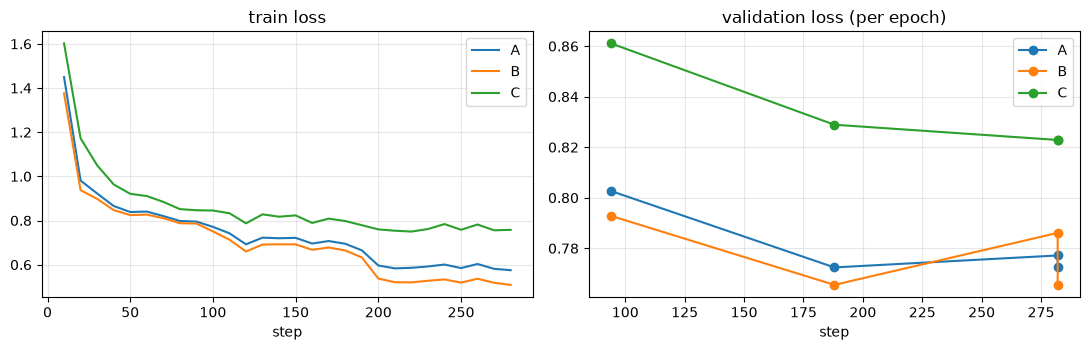

In [12]:
from IPython.display import display
import matplotlib.pyplot as plt

METRICS = ["schema_valid_rate", "queue_acc", "type_acc", "priority_acc", "labels_exact_match",
           "queue_macro_f1", "priority_macro_f1", "rougeL_resolution", "tokens_per_sec"]
KEY = ["schema_valid_rate", "labels_exact_match", "queue_macro_f1", "priority_macro_f1", "rougeL_resolution"]

def load_runs(d, smoke=False):
    # read every run_*.json; skip the loss-history files and keep smoke runs separate from real runs
    runs = []
    for p in sorted(Path(d).glob("run_*.json")):
        if p.name.endswith("_log.json") or p.name.endswith("_smoke.json") != smoke:
            continue
        runs.append(json.loads(p.read_text()))
    return runs

def comparison_table(runs, baseline):
    rows = {}
    for m, r in (baseline or {}).get("results", {}).items():   # Week 1 zero-shot / few-shot rows first
        rows[f"baseline · {m}"] = {k: r.get(k) for k in METRICS}
    for r in runs:
        rows[r["run_id"]] = {k: r["test"].get(k) for k in METRICS} | {"val_loss": r["train"].get("val_loss")}
    return pd.DataFrame(rows).T

def ablation_table(runs, ref_id, ref_cfg):
    by = {r["run_id"]: r for r in runs if r.get("kind", "sft") == "sft"}
    if ref_id not in by:
        return None
    rows = {}
    for rid, r in by.items():
        if rid == ref_id:
            continue
        fac = diff_factors(r["config"], ref_cfg)
        if len(fac) != 1 or fac == ["seed"]:          # only clean one-factor changes, and seeds are handled separately
            continue
        # Δ = this run minus the reference run (positive = better for these metrics), plus what the run cost
        d = {f"Δ {k}": r["test"][k] - by[ref_id]["test"][k] for k in KEY}
        d |= {"Δ val_loss": r["train"]["val_loss"] - by[ref_id]["train"]["val_loss"],
              "trainable %": r["train"]["pct_trainable"], "train min": r["train"]["train_sec"] / 60,
              "peak GB": r["train"]["peak_mem_gb"]}
        rows[f"{rid} ({fac[0]})"] = d
    return pd.DataFrame(rows).T if rows else None

def seed_variance(runs, ref_cfg):
    # runs with the reference config but different seeds: their spread is the "noise level" of the experiment
    same = [r for r in runs if r.get("kind", "sft") == "sft"
            and all(r["config"][k] == ref_cfg[k] for k in ["r", "alpha", "lr", "targets", "epochs"])]
    if len(same) < 2:
        return None
    df = pd.DataFrame([r["test"] for r in same])[KEY]
    return pd.DataFrame({"mean": df.mean(), "std": df.std(ddof=1), "n_seeds": len(df)})

baseline = json.loads((W1 / "baseline_results.json").read_text()) if (W1 / "baseline_results.json").exists() else None
runs = load_runs(OUT, smoke=SMOKE)
assert runs, f"no run_*.json found in {OUT}; train at least one run first"

tbl = comparison_table(runs, baseline)
pct = ["schema_valid_rate", "queue_acc", "type_acc", "priority_acc", "labels_exact_match"]
# pretty-print: rates as %, F1/ROUGE with 3 decimals, and a green gradient on the key columns
display(tbl.style.format({**{c: "{:.1%}" for c in pct}, "queue_macro_f1": "{:.3f}", "priority_macro_f1": "{:.3f}",
                          "rougeL_resolution": "{:.3f}", "tokens_per_sec": "{:.1f}", "val_loss": "{:.4f}"}, na_rep="-")
        .background_gradient(cmap="Greens", subset=KEY))

abl = ablation_table(runs, REF_RUN, RUNS[REF_RUN])
if abl is not None:
    print(f"\nOne-factor ablations vs reference {REF_RUN}:")
    display(abl.style.format("{:+.3f}", subset=[c for c in abl.columns if c.startswith("Δ")])
            .format({"trainable %": "{:.2f}", "train min": "{:.1f}", "peak GB": "{:.1f}"}))
sv = seed_variance(runs, RUNS[REF_RUN])
if sv is not None:
    print("\nReference config across seeds:"); display(sv.round(4))

# Loss curves: left = training loss per logging step, right = validation loss per epoch (rising val loss = overfitting)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for r in runs:
    lp = OUT / f"run_{r['run_id']}_log.json"
    if not lp.exists():
        continue
    h = json.loads(lp.read_text())
    ax[0].plot([x["step"] for x in h if "loss" in x], [x["loss"] for x in h if "loss" in x], label=r["run_id"])
    ev = [(x["step"], x["eval_loss"]) for x in h if "eval_loss" in x]
    if ev:
        ax[1].plot(*zip(*ev), marker="o", label=r["run_id"])
ax[0].set(title="train loss", xlabel="step"); ax[1].set(title="validation loss (per epoch)", xlabel="step")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

### Step 5b · The results report (written automatically from your run files)

**What the next cell does**

The tables above show the numbers; this cell **reads them for you** and writes the findings as plain sentences, so the results are documented the same way every time and nothing is pre-filled or copied from another run. It needs no GPU and can be re-run whenever a new `run_*.json` appears (for example after a teammate's run or the DPO stretch).

**What it reports, in order**

1. **The best run, chosen by validation loss** (never by the test score), with its configuration.
2. **Best run vs the Week 1 baselines** for schema validity, exact label match, queue/priority macro-F1 and ROUGE-L. For the two rate metrics (schema validity and exact label match) it adds a **noise check**: the difference is called *beyond noise* only if it exceeds about two standard errors, where the standard error of a rate $p$ on $n$ tickets is $\sqrt{p(1-p)/n}$. This is deliberately conservative (it treats the two systems as independent); the Week 3 notebook uses the more sensitive paired bootstrap.
3. **Best run vs the majority-class floor** for the three label accuracies. The floor is "always answer the most common training label". A model that does not clear it has learned nothing about the labels, however good its accuracy looks (the Week 1 analysis showed the base model barely cleared it for `queue` and fell below it for `priority`).
4. **Overfitting check**: the validation loss after each epoch from the saved log. If the last epoch is clearly worse than the best one, the adapter you keep is the *earlier* epoch (that is what `load_best_model_at_end` does), and the report says so.
5. **Ablation sentences**: for each one-factor variant, the change in queue macro-F1, ROUGE-L and validation loss, its cost (trainable parameters, training minutes), and whether the change is larger than the **seed-to-seed standard deviation** when seed runs exist. Without seed runs the report says so instead of claiming a winner.
6. **Cost**: trainable-parameter share, training time, peak GPU memory and generation speed of the best run.

**What to look for:** sentences that say *within noise* are not failures of the notebook; with 180 test tickets they are often the honest conclusion, and they belong in the report as such.

In [13]:
from IPython.display import Markdown

def results_report():
    n = len(test_rows)
    sft = [r for r in runs if r.get("kind", "sft") == "sft"]
    best = min(sft, key=lambda r: r["train"]["val_loss"])           # chosen by VALIDATION loss, never by the test score
    c, t = best["config"], best["test"]
    bl = (baseline or {}).get("results", {})
    L = ["#### Results report (auto-generated from the run files)\n",
         f"**Best run by validation loss: `{best['run_id']}`** (validation loss {best['train']['val_loss']:.4f}; rank {c['r']}, "
         f"learning rate {c['lr']}, adapter on `{c['targets']}` layers, {c['epochs']} epochs). Evidence: {n} held-out test tickets.\n"]

    # --- 1. best run vs the Week 1 baselines (with a conservative noise check for rates)
    rows = [("schema_valid_rate", "schema-valid rate", True), ("labels_exact_match", "all three labels exact", True),
            ("queue_macro_f1", "queue macro-F1", False), ("priority_macro_f1", "priority macro-F1", False),
            ("rougeL_resolution", "ROUGE-L of the reply", False)]
    L.append("| Metric | zero-shot | few-shot | best run | change vs the better baseline | verdict |\n|---|---|---|---|---|---|")
    for k, lab, is_rate in rows:
        z, f, b = bl.get("zero_shot", {}).get(k), bl.get("few_shot", {}).get(k), t[k]
        ref = max(v for v in [z, f] if v is not None) if (z is not None or f is not None) else None
        fmt = (lambda v: "-" if v is None else (f"{v:.1%}" if is_rate else f"{v:.3f}"))
        if ref is None:
            L.append(f"| {lab} | {fmt(z)} | {fmt(f)} | {fmt(b)} | - | no baseline found |"); continue
        d = b - ref
        if is_rate:
            se = np.sqrt(b * (1 - b) / n + ref * (1 - ref) / n)      # unpaired, therefore conservative
            verdict = "beyond noise" if abs(d) >= 2 * se else "within noise"
            ds = f"{100 * d:+.1f} pp"
        else:
            verdict, ds = "no interval for this metric; judge by direction and size", f"{d:+.3f}"
        L.append(f"| {lab} | {fmt(z)} | {fmt(f)} | {fmt(b)} | {ds} | {verdict} |")

    # --- 2. majority-class floor (training labels only)
    maj = {k: pd.Series([r[k] for r in train_rows]).mode()[0] for k in ["queue", "type", "priority"]}
    L.append("\n**Versus the majority-class floor** (always answer the most common training label):\n")
    for k in ["queue", "type", "priority"]:
        fl = float(np.mean([r[k] == maj[k] for r in test_rows])); acc = t[f"{k}_acc"]
        L.append(f"- {k}: floor {fl:.1%} (`{maj[k]}`), best run {acc:.1%} -> " + ("clears the floor" if acc > fl else "does **not** clear the floor"))

    # --- 3. overfitting check from the saved loss log
    lp = OUT / f"run_{best['run_id']}_log.json"
    if lp.exists():
        ev = [x["eval_loss"] for x in json.loads(lp.read_text()) if "eval_loss" in x]
        if ev:
            be = int(np.argmin(ev)) + 1
            msg = f"validation loss per epoch: {', '.join(f'{v:.3f}' for v in ev)}; best after epoch {be}"
            msg += ("; the last epoch is clearly worse, i.e. **overfitting**: the kept adapter is the best epoch, not the last one"
                    if ev[-1] > min(ev) * 1.02 else "; no sign of overfitting")
            L.append(f"\n**Overfitting check:** {msg}.")

    # --- 4. ablations vs the reference run, judged against seed noise when seed runs exist
    if abl is not None:
        L.append("\n**One-factor ablations** (each differs from the reference run `%s` in exactly one setting):\n" % REF_RUN)
        for name, r in abl.iterrows():
            dq, dr, dv = r["Δ queue_macro_f1"], r["Δ rougeL_resolution"], r["Δ val_loss"]
            s = (f"- {name}: queue macro-F1 {dq:+.3f}, ROUGE-L {dr:+.3f}, validation loss {dv:+.3f}; "
                 f"{r['trainable %']:.2f}% trainable parameters, {r['train min']:.0f} min of training.")
            if sv is not None:
                sd = sv.loc["queue_macro_f1", "std"]
                s += (f" The queue macro-F1 change is {'larger' if abs(dq) > 2 * sd else 'not larger'} than twice the seed-to-seed std ({sd:.3f}), "
                      f"so it is {'probably real' if abs(dq) > 2 * sd else 'not distinguishable from noise'}.")
            else:
                s += " No seed runs yet (`B_s7`, `B_s13`), so the noise level is unknown and no winner should be claimed."
            L.append(s)

    # --- 5. cost
    L.append(f"\n**Cost of the best run:** {best['train']['pct_trainable']:.2f}% of the parameters trained, "
             f"{best['train']['train_sec'] / 60:.0f} minutes, peak GPU memory {best['train']['peak_mem_gb']:.1f} GiB, "
             f"generation speed {t['tokens_per_sec']:.1f} tokens/s (HF generate, 4-bit, LoRA unmerged).")
    return "\n".join(L)

display(Markdown(results_report()))

#### Results report (auto-generated from the run files)

**Best run by validation loss: `B`** (validation loss 0.7655; rank 16, learning rate 0.0002, adapter on `all` layers, 3 epochs). Evidence: 180 held-out test tickets.

| Metric | zero-shot | few-shot | best run | change vs the better baseline | verdict |
|---|---|---|---|---|---|
| schema-valid rate | 100.0% | 100.0% | 100.0% | +0.0 pp | beyond noise |
| all three labels exact | 20.0% | 23.9% | 28.9% | +5.0 pp | within noise |
| queue macro-F1 | 0.494 | 0.435 | 0.475 | -0.018 | no interval for this metric; judge by direction and size |
| priority macro-F1 | 0.379 | 0.431 | 0.242 | -0.189 | no interval for this metric; judge by direction and size |
| ROUGE-L of the reply | 0.220 | 0.256 | 0.312 | +0.056 | no interval for this metric; judge by direction and size |

**Versus the majority-class floor** (always answer the most common training label):

- queue: floor 64.4% (`Technical Support`), best run 67.2% -> clears the floor
- type: floor 50.0% (`Incident`), best run 78.3% -> clears the floor
- priority: floor 53.9% (`high`), best run 53.3% -> does **not** clear the floor

**Overfitting check:** validation loss per epoch: 0.793, 0.766, 0.786, 0.766; best after epoch 2; no sign of overfitting.

**One-factor ablations** (each differs from the reference run `B` in exactly one setting):

- A (rank): queue macro-F1 -0.007, ROUGE-L -0.005, validation loss +0.007; 0.26% trainable parameters, 17 min of training. No seed runs yet (`B_s7`, `B_s13`), so the noise level is unknown and no winner should be claimed.
- C (targets): queue macro-F1 -0.017, ROUGE-L -0.006, validation loss +0.057; 0.07% trainable parameters, 11 min of training. No seed runs yet (`B_s7`, `B_s13`), so the noise level is unknown and no winner should be claimed.

**Cost of the best run:** 0.53% of the parameters trained, 17 minutes, peak GPU memory 12.7 GiB, generation speed 107.6 tokens/s (HF generate, 4-bit, LoRA unmerged).

### Step 5c · How to read the Week 2 tables, and what to expect given Week 1

**Where Week 1 left us.** The base model already produced valid JSON almost every time (100% parsed, 99.4–100% schema-valid), but it was weak where the *dataset's own conventions* decide: queue accuracy was no better than always answering `Technical Support` (about 64%), priority accuracy was below always answering `high` (about 56%), the rare `IT Support` queue was almost never predicted (recall 12.5% zero-shot, 2.1% few-shot), and ROUGE-L of the reply was only 0.22–0.26. So the question for Week 2 is not *"can fine-tuning teach the format?"* (it is already known) but ***"can it learn the label conventions and the reply style?"***

**The comparison table (Step 5)**

| Column group | What it tells you | Typical pitfall |
|---|---|---|
| `schema_valid_rate`, `json_parse_rate` | Does the model follow the output contract? Expect ~100% for every row, so this column cannot separate the runs | Celebrating "+0.6 pp" that is one ticket |
| `queue_acc`, `type_acc`, `priority_acc` | Share of tickets with the right label | Reading accuracy without the majority-class floor on an imbalanced label |
| `queue_macro_f1`, `priority_macro_f1` | Average F1 over classes, so the rare class counts as much as the common one | Ignoring it: this is the metric that reveals "always answers the biggest class" |
| `labels_exact_match` | All three labels right at once; the strictest label metric | Low values are normal (the three are separate decisions) |
| `rougeL_resolution` | Overlap of the reply with the reference reply | Treating it as absolute quality: replies are paraphrastic, so use it only to rank systems |
| `tokens_per_sec` | Generation speed, HF `generate`, 4-bit, adapter **not merged** | Comparing with Week 4 vLLM numbers: different stack |
| `val_loss` | Cross-entropy on the validation answers (lower = better fit) | Comparing it across different tokenizers or data; here it is only comparable between runs of this grid |

**The ablation table**: each row is one run minus the reference run `B`, with a `Δ` in front of every metric (positive = better for the quality metrics; for `Δ val_loss` negative = better). It also shows what the run *cost*: trainable-parameter share, training minutes and peak GPU memory. A smaller adapter (run `A`, rank 8; run `C`, `q,v` layers only) that scores the same as `B` is the better engineering choice.

**The seed table**: the same configuration trained with different random seeds. Its standard deviation is the **noise floor** of the whole grid. A difference between two runs smaller than about twice that standard deviation should not be reported as an improvement.

**The loss curves**: the left plot is the training loss per logging step; the right plot is the validation loss after each epoch. If the training loss keeps falling while the validation loss turns upward, the model is memorising; the best-epoch adapter is the one saved.

**Rules of thumb for the write-up**

1. A gain you can defend: it beats the **better of the two Week 1 baselines**, clears the **majority-class floor**, and is larger than the **seed noise** (or beyond about two standard errors for a rate).
2. With 180 test tickets, one ticket is 0.56 pp; changes of 1–3 pp are usually noise.
3. If no run clears the floor on `priority`, say so plainly: it points at label noise in the synthetic data, a limitation that belongs in the model card, not a bug to hide.
4. Keep the test set for the final number. Every choice (best epoch, best run, ablation conclusions) was made from the **validation** loss.

**Next:** `it_helpdesk_week3_rag.ipynb` picks the run with the lowest validation loss from these `run_*.json` files automatically (override with `FT_RUN`) and adds retrieval on top of it.

## 2 · Analysis to write up (report section 5)

Answer these from your own tables and loss curves. Leave the numbers blank until you have run them.

1. **Gain over baseline:** which metrics moved most vs zero-shot *and* few-shot (schema validity, label F1, ROUGE-L)? Is the gain mostly format or content? → ___
2. **Rank:** did $r=8$ (A) match $r=16$ (B)? What does that say about the capacity this task needs? → ___
3. **Ablation:** how much did training all linear layers (B) add over `q,v` only (C), and at what cost in trainable parameters, time and memory? → ___
4. **Overfitting check:** compare train vs validation loss per epoch. Which epoch was best, and does the val-loss minimum agree with the test metrics? → ___
5. **Run-to-run noise:** if you ran seeds, is the B-vs-C gap larger than the seed std? If not, say so rather than claiming a win. → ___
6. **Failure modes:** open `preds_<run>.jsonl`, filter `schema_valid == False` or wrong queue, and list 3 recurring error patterns. → ___
7. **Speed:** tokens/s here is HF `generate` in 4-bit with LoRA unmerged; Week 4 re-measures on vLLM. → ___

> [!note] Small test set
> With 180 test rows, a 1-point change is ~2 examples. Prefer consistent direction across several metrics over any single number.

## 3 · Optional stretch: rejection sampling → DPO (alignment-lite)

Only attempt this if the SFT runs above finished cleanly. Set `RUN_DPO = True` in the config cell.

1. Sample $n$ completions per **train** prompt from the best SFT adapter.
2. Score each with the same rule-based reward used for evaluation (schema validity + label match + ROUGE-L, max 3.0).
3. Build a preference pair per prompt: *chosen* = reference JSON, *rejected* = the lowest-reward sample, kept only if the reward gap is large enough.
4. Train with DPO, which maximises the margin between chosen and rejected relative to the frozen reference policy:

$$\mathcal{L}_{DPO}=-\log\sigma\!\Big(\beta\Big[\log\tfrac{\pi_\theta(y_w|x)}{\pi_{ref}(y_w|x)}-\log\tfrac{\pi_\theta(y_l|x)}{\pi_{ref}(y_l|x)}\Big]\Big)$$

With LoRA, $\pi_{ref}$ is the same model with the adapter switched off, so no second copy is loaded. Pairs come from the train split only; test is evaluated once at the end, same as the SFT runs.

### Step 6a · (Optional) Build the preference pairs

**What the next cell does**

Only does real work when `RUN_DPO = True`; otherwise it defines two helper functions and prints "skipping". It loads the best SFT adapter, lets the model write several answers per training ticket, and turns the best/worst answers into *preference pairs* for DPO.

**The pieces**

- `DPO` is the settings dictionary: which adapter to start from, how many prompts and samples per prompt, the sampling temperature and top-p (sampling is *random*, so the model produces varied answers), `min_gap` (how much worse the rejected answer must be), `beta` (how strongly DPO pulls toward the chosen answer), learning rate and epochs.
- `select_pair(...)` builds one pair: **chosen** is the reference (gold) JSON with reward 3.0, **rejected** is the lowest-scoring sampled answer. If the gap is smaller than `min_gap`, or the model reproduced the gold answer exactly, there is no clear lesson and the ticket is skipped.
- `sample_completions(...)` generates `n` random answers per ticket in one call (`num_return_sequences`).

**When enabled**

1. Loads the base model and the adapter `DPO["base_run"]` with `is_trainable=True`, so DPO can continue training it.
2. Samples prompts **from the train split only** (and asserts none is a test ticket), generates answers two tickets at a time (to keep memory low), builds the pairs and writes them to `dpo_pairs.jsonl`.
3. Prints the number of pairs, the mean reward gap and how many rejected answers were schema-invalid. The next cell then trains on these pairs and releases the memory.

In [14]:
DPO = dict(base_run="B", n_prompts=250, n_samples=4, temperature=0.8, top_p=0.95, min_gap=0.5, beta=0.1, lr=5e-6, epochs=1)

def select_pair(gold_row, samples, min_gap):
    """Rejected = lowest-reward sample; chosen = gold JSON (reward 3.0). None if no clear negative."""
    gold_json = json.dumps({"queue": gold_row["queue"], "type": gold_row["type"], "priority": gold_row["priority"],
                            "resolution": gold_row["answer"]}, ensure_ascii=False)
    rewards = [pair_reward(s, gold_row) for s in samples]
    j = int(np.argmin(rewards))                       # index of the worst sampled answer
    gap = pair_reward(gold_json, gold_row) - rewards[j]
    if gap < min_gap or samples[j].strip() == gold_json:
        return None                                   # no clear lesson in this pair
    return {"uid": gold_row["uid"], "prompt": msgs_for(gold_row),
            "chosen": [{"role": "assistant", "content": gold_json}],
            "rejected": [{"role": "assistant", "content": samples[j]}], "gap": gap}

def sample_completions(model, rows, n, temperature, top_p):
    tok.padding_side = "left"
    enc = tok([render(msgs_for(r), True) for r in rows], return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    with torch.inference_mode():
        # do_sample=True + num_return_sequences=n -> n different random answers per prompt
        out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=True, temperature=temperature, top_p=top_p,
                             num_return_sequences=n, pad_token_id=tok.pad_token_id, use_cache=True)
    texts = tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [texts[i * n:(i + 1) * n] for i in range(len(rows))]   # regroup the flat list: n answers per prompt

if RUN_DPO:
    check_gpu_free(min_free_gib=10)                   # same pre-flight as before the SFT runs
    from peft import PeftModel, prepare_model_for_kbit_training
    seed_everything(42)
    dpo_base, dpo_dtype = load_base()
    dpo_base = prepare_model_for_kbit_training(dpo_base, use_gradient_checkpointing=True, gradient_checkpointing_kwargs={"use_reentrant": False})
    # continue from the saved SFT adapter; is_trainable=True keeps its weights trainable for DPO
    dpo_model = PeftModel.from_pretrained(dpo_base, OUT / "adapters" / DPO["base_run"], is_trainable=True)
    dpo_model.eval()

    # pairs come from TRAIN prompts only, and we assert that no test ticket slipped in
    prompts = random.Random(42).sample(train_rows, min(DPO["n_prompts"], len(train_rows)))
    assert {r["uid"] for r in prompts}.isdisjoint({r["uid"] for r in test_rows})
    pairs, step = [], 2                               # 2 tickets x 4 samples at a time keeps generation memory low
    for i in range(0, len(prompts), step):
        b = prompts[i:i + step]
        for r, samples in zip(b, sample_completions(dpo_model, b, DPO["n_samples"], DPO["temperature"], DPO["top_p"])):
            p = select_pair(r, samples, DPO["min_gap"])
            if p: pairs.append(p)
    with open(OUT / "dpo_pairs.jsonl", "w", encoding="utf-8") as f:
        f.writelines(json.dumps(p, ensure_ascii=False) + "\n" for p in pairs)
    print(f"{len(pairs)} pairs from {len(prompts)} prompts | mean gap {np.mean([p['gap'] for p in pairs]):.2f}")
    print("rejected that are schema-invalid:", np.mean([extract_json(p['rejected'][0]['content']) is None for p in pairs]).round(3))
else:
    print("RUN_DPO=False; skipping pair construction.")

RUN_DPO=False; skipping pair construction.


### Step 6b · (Optional) DPO training and evaluation

**What the next cell does**

When `RUN_DPO = True`, it trains the SFT adapter further with **DPO (Direct Preference Optimization)** on the pairs from the previous cell, evaluates the result on the test set exactly like the SFT runs, saves a result file and **releases the GPU memory**. Otherwise it just prints "skipping".

**Step by step**

1. A safety assert requires at least 50 pairs; fewer would not teach anything reliable.
2. `DPOConfig` holds the settings. Learning rate is tiny (5e-6) because DPO should only *nudge* a model that is already good. `beta` controls how strongly it moves toward the chosen answers, and warm-up is 10% of the steps (`warmup_steps=0.1`, a fraction, as in the SFT runs). Batch size 1 with 8 accumulation steps keeps memory low.
3. `DPOTrainer` is created with `ref_model=None`: with LoRA the *reference policy* is simply the same model with the adapter switched off, so no second copy of the 7B model is needed. The `try/except` handles a library rename (`tokenizer` became `processing_class`).
4. Train, save the new adapter as `B_dpo` and the loss history, then `del trainer` and `free_gpu` (the trainer holds the optimizer state, several GB, which must go before generating), and score the test set once with the same function as Week 1/SFT.
5. Write `run_B_dpo.json`; re-run the aggregation cell to see it in the comparison table. Its peak memory is measured across all GPUs from `reset_peak()` onward.
6. `release_model(dpo_model)` frees the weights' GPU storage, then `del dpo_model, dpo_base, ds` drops the remaining references and `free_gpu` returns the memory, so you can run the cleanup cell or another notebook right afterwards.

In [15]:
if RUN_DPO:
    from trl import DPOTrainer, DPOConfig
    from datasets import Dataset
    assert len(pairs) >= 50, "too few preference pairs; raise n_prompts or lower min_gap"
    ds = Dataset.from_list([{k: p[k] for k in ["prompt", "chosen", "rejected"]} for p in pairs])
    # tiny learning rate: DPO should only nudge a model that is already good; warmup_steps < 1 = fraction of all steps
    cfg = DPOConfig(output_dir=str(OUT / "ckpt" / "dpo"), per_device_train_batch_size=1, gradient_accumulation_steps=8,
                    num_train_epochs=DPO["epochs"], learning_rate=DPO["lr"], beta=DPO["beta"], max_length=MAX_LEN,
                    lr_scheduler_type="cosine", warmup_steps=0.1, logging_steps=5, save_strategy="no", optim="paged_adamw_8bit",
                    bf16=dpo_dtype == torch.bfloat16, fp16=dpo_dtype == torch.float16, gradient_checkpointing=True,
                    report_to="wandb" if USE_WANDB else "none", run_name="w2_dpo", seed=42)
    try:                                              # TRL renamed tokenizer -> processing_class
        trainer = DPOTrainer(model=dpo_model, ref_model=None, args=cfg, train_dataset=ds, processing_class=tok)
    except TypeError:
        trainer = DPOTrainer(model=dpo_model, ref_model=None, args=cfg, train_dataset=ds, tokenizer=tok)
    reset_peak(); t0 = time.time(); trainer.train(); dpo_sec = time.time() - t0
    tag = f"{DPO['base_run']}_dpo"
    dpo_model.save_pretrained(OUT / "adapters" / tag)
    (OUT / f"run_{tag}_log.json").write_text(json.dumps(trainer.state.log_history))
    del trainer; free_gpu("DPO training done, before test evaluation: ")   # drop the optimizer state before generating
    metrics = evaluate_on_test(dpo_model, tag)        # same test evaluation as every SFT run
    res = {"run_id": tag, "kind": "dpo", "config": {**RUNS[DPO["base_run"]], "dpo": DPO, "note": "SFT + DPO"},
           "train": {"train_sec": dpo_sec, "n_pairs": len(pairs), "val_loss": None, "pct_trainable": None,
                     "peak_mem_gb": peak_gib()},
           "test": metrics, "model": MODEL_ID, "smoke": SMOKE, "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")}
    (OUT / f"run_{tag}.json").write_text(json.dumps(res, indent=2))
    print(tag, {k: round(v, 3) for k, v in metrics.items() if k in KEY})
    print("Re-run the aggregation cell to add this row to the comparison table.")
    release_model(dpo_model)                      # free the weights' GPU storage even if a library still references the module
    del dpo_model, dpo_base, ds                   # DPO is finished: release the model and the dataset
    free_gpu("after DPO: ")
else:
    print("RUN_DPO=False; skipping.")

RUN_DPO=False; skipping.


### Step 7 · Free the GPU memory (run this when you are done)

**What the next cell does**

Training and DPO already release their memory when they finish, but variables from interactive experiments (a model you loaded by hand, a leftover trainer, a batch of tensors) can still be alive. This cell removes them and returns the memory to the GPU driver. **Run it when you are finished, and before opening another GPU notebook** (for example Week 3). A forgotten kernel on a shared GPU is the most common cause of `CUDA out of memory` in a *different* notebook.

**Step by step**

1. `gpu_report("before: ")` shows the memory in use now.
2. We delete every global name that may hold GPU tensors, and call `release_model()` on any module we find: it swaps the weights for empty tensors, which frees the GPU storage even if some library still references the module. `globals().pop(name, None)` removes a variable if it exists and silently ignores it if not, so the cell is safe to run twice.
3. `free_gpu()` clears saved tracebacks, runs the garbage collector and returns cached memory to the driver; it prints the "after" report.
4. **Full shutdown (on by default).** With `SHUTDOWN_WHEN_DONE = True` (the default) the cell ends by stopping the kernel process, the only way to give back 100% of the GPU memory (the CUDA runtime itself keeps roughly 0.3-0.5 GB until the process exits). The exit is scheduled by a 3-second timer so that **this cell finishes normally first**; exiting inside the cell would leave it showing "running" forever. About 3 seconds later VS Code reports the kernel as stopped or "died"; that is expected. Everything is saved on disk, and the aggregation cell works again after a restart. Set it to `False` to keep the kernel alive.

If memory stays high, something still refers to the model; *Kernel > Restart* always works.

In [16]:
gpu_report("before: ")

# Drop every global that may still hold GPU tensors (pop() ignores names that don't exist, so re-running is safe)
for name in ["trainer", "model", "base", "dpo_model", "dpo_base", "ds", "enc", "out"]:
    obj = globals().pop(name, None)
    if isinstance(obj, torch.nn.Module):
        release_model(obj)                    # free the weights' GPU storage even if something still references the module
free_gpu("after:  ")                      # clear tracebacks, garbage-collect, return cached memory to the driver

# Optional: end the process, because only a process exit releases the CUDA runtime's own ~0.3-0.5 GB
if SHUTDOWN_WHEN_DONE:
    import threading
    print("Shutting the kernel down in 3 seconds to free ALL GPU memory. Results are saved on disk.")
    sys.stdout.flush(); sys.stderr.flush()
    # exit from a timer thread, AFTER this cell has finished: exiting inside the cell would leave it "running" forever
    threading.Timer(3.0, os._exit, args=(0,)).start()

before: GPU 0: 0.7/44.4 GiB used | this kernel: 0.0 GiB allocated, 0.1 GiB reserved


after:  GPU 0: 0.7/44.4 GiB used | this kernel: 0.0 GiB allocated, 0.1 GiB reserved
Shutting the kernel down in 3 seconds to free ALL GPU memory. Results are saved on disk.


## 4 · Week 2 checklist

- [ ] SHA-256 check passed (frozen data unchanged since Week 1)
- [ ] At least two different configurations plus the ablation have finished (e.g. B, A, C), and every team member has trained one run
- [ ] `run_*.json`, `run_*_log.json`, `preds_*.jsonl` committed; adapters stored (W&B artefacts, Drive, or git-lfs)
- [ ] Comparison table includes the Week 1 baselines and every run, and the analysis questions are answered
- [ ] Best run chosen **by validation loss and validation-style decisions**, not by looking at test
- [ ] DPO / rejection sampling attempted only if everything above is clean
- [ ] Step 7 run (GPU memory released) before starting any other GPU notebook

**Hand-off to Week 3 (`it_helpdesk_week3_rag.ipynb`):** `adapters/<best run>` is the model for RAG; the Week 3 notebook selects it by validation loss from the `run_*.json` files. Keep `SYSTEM`, decoding and the 4-bit load unchanged for the three-way comparison: base + RAG vs fine-tuned vs fine-tuned + RAG.